# Rigor checks for Part A

Do the Part A results survive reasonable changes to the analysis choices? Run `01_pbmc3k_scanpy.ipynb` first.

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

SEED = 0
sc.logging.print_header()  # package versions, for reproducibility
FIG = Path("../results/figures"); TAB = Path("../results/tables")
adata = sc.read_h5ad("../data/processed/pbmc3k_processed.h5ad")
assert "cell_type" in adata.obs, "Finish the cell-type mapping in notebook 01 first."
reference = adata.obs["leiden"].astype(str).values
adata

AnnData object with n_obs × n_vars = 2638 × 1838
    obs: 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'cell_type'
    var: 'gene_ids', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'cell_type_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'tsne', 'umap'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

## R1. Can a classifier recover the cell types from principal components?

Features are the first 20 PCs. Labels are your cell types. 5-fold stratified cross-validation keeps each cell type's share the same in every fold. We report balanced accuracy too, because platelets and dendritic cells are small groups that plain accuracy can hide.

**What this does and doesn't show.** The labels came from clustering on these same PCs, so high accuracy is partly built in. It shows the clusters are well separated and consistent in PCA space. It does not show the cell types are biologically correct. Very small cell types (fewer than 5 cells) would break stratified 5-fold, so they are dropped here and noted.

In [2]:
X = adata.obsm["X_pca"][:, :20]
y = adata.obs["cell_type"].astype(str).values
counts = pd.Series(y).value_counts()
small = counts[counts < 5].index.tolist()
if small:
    print("Dropped (fewer than 5 cells):", small)
mask = ~np.isin(y, small)
X, y = X[mask], y[mask]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
models = {
    "logistic_regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "random_forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
}
rows = []
for name, model in models.items():
    s = cross_validate(model, X, y, cv=cv, scoring=["accuracy", "balanced_accuracy"])
    rows.append({
        "model": name,
        "accuracy_mean": s["test_accuracy"].mean(), "accuracy_sd": s["test_accuracy"].std(),
        "balanced_acc_mean": s["test_balanced_accuracy"].mean(), "balanced_acc_sd": s["test_balanced_accuracy"].std(),
    })
clf_df = pd.DataFrame(rows).round(4)
clf_df.to_csv(TAB / "pbmc_classifier_cv.csv", index=False)
clf_df

,model,accuracy_mean,accuracy_sd,balanced_acc_mean,balanced_acc_sd
0,logistic_regression,0.9602,0.0088,0.9429,0.0112
1,random_forest,0.9591,0.0087,0.9149,0.0406


## R2. Clustering resolution sweep

How does the number of clusters change with resolution, and how similar is each result to the resolution 0.9 reference? The **adjusted Rand index (ARI)** is 1 for identical partitions and about 0 for random agreement. It doesn't need cluster numbers to match.

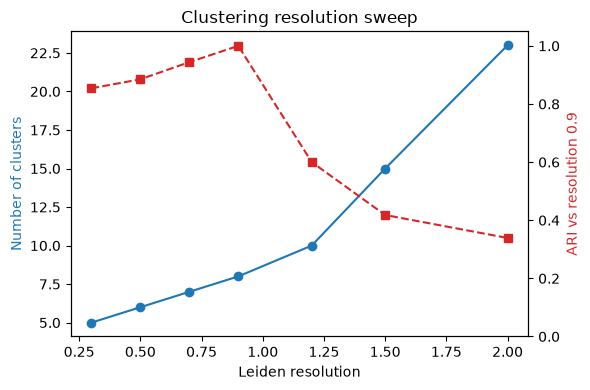

,resolution,n_clusters,ARI_vs_res0.9
0,0.3,5,0.854
1,0.5,6,0.885
2,0.7,7,0.944
3,0.9,8,1.000
4,1.2,10,0.600
5,1.5,15,0.418
6,2.0,23,0.339


In [3]:
resolutions = [0.3, 0.5, 0.7, 0.9, 1.2, 1.5, 2.0]
rows = []
for r in resolutions:
    key = f"leiden_r{r}"
    sc.tl.leiden(adata, resolution=r, key_added=key, random_state=SEED,
                 flavor="igraph", n_iterations=2, directed=False)
    rows.append({"resolution": r, "n_clusters": adata.obs[key].nunique(),
                 "ARI_vs_res0.9": adjusted_rand_score(reference, adata.obs[key])})
res_df = pd.DataFrame(rows).round(3)
res_df.to_csv(TAB / "pbmc_resolution_sweep.csv", index=False)

fig, ax1 = plt.subplots(figsize=(6, 4))
ax1.plot(res_df.resolution, res_df.n_clusters, "o-", color="tab:blue")
ax1.set_xlabel("Leiden resolution"); ax1.set_ylabel("Number of clusters", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(res_df.resolution, res_df["ARI_vs_res0.9"], "s--", color="tab:red")
ax2.set_ylabel("ARI vs resolution 0.9", color="tab:red"); ax2.set_ylim(0, 1.05)
plt.title("Clustering resolution sweep"); plt.tight_layout()
plt.savefig(FIG / "pbmc_resolution_sweep.png", dpi=150); plt.show()
res_df

## R3. Seed sensitivity

Leiden is randomized. If a different seed gives a very different partition, the clusters are fragile.

In [4]:
rows = []
for seed in range(10):
    key = f"leiden_seed{seed}"
    sc.tl.leiden(adata, resolution=0.9, key_added=key, random_state=seed,
                 flavor="igraph", n_iterations=2, directed=False)
    rows.append({"seed": seed, "n_clusters": adata.obs[key].nunique(),
                 "ARI_vs_reference": adjusted_rand_score(reference, adata.obs[key])})
seed_df = pd.DataFrame(rows).round(3)
seed_df.to_csv(TAB / "pbmc_seed_sensitivity.csv", index=False)
print("ARI range:", seed_df.ARI_vs_reference.min(), "to", seed_df.ARI_vs_reference.max())
seed_df

ARI range: 0.949 to 1.0


,seed,n_clusters,ARI_vs_reference
0,0,8,1.000
1,1,8,0.971
2,2,8,0.978
3,3,8,0.998
4,4,8,0.975
5,5,8,0.995
6,6,7,0.949
7,7,8,0.990
8,8,8,0.971
9,9,8,0.996


## R4. Number of PCs

The neighbor graph was built from 40 PCs. Rebuild it from 10, 20 and 30 and compare the clusters.

In [5]:
rows = []
for n_pcs in [10, 20, 30, 40]:
    tmp = adata.copy()
    sc.pp.neighbors(tmp, n_neighbors=10, n_pcs=n_pcs, random_state=SEED)
    sc.tl.leiden(tmp, resolution=0.9, key_added="l", random_state=SEED,
                 flavor="igraph", n_iterations=2, directed=False)
    rows.append({"n_pcs": n_pcs, "n_clusters": tmp.obs["l"].nunique(),
                 "ARI_vs_reference": adjusted_rand_score(reference, tmp.obs["l"])})
pcs_df = pd.DataFrame(rows).round(3)
pcs_df.to_csv(TAB / "pbmc_npcs_sensitivity.csv", index=False)
pcs_df

,n_pcs,n_clusters,ARI_vs_reference
0,10,11,0.541
1,20,9,0.668
2,30,8,0.884
3,40,8,1.000


## Interpretation

**Classifiers.** From the first 20 PCs, logistic regression recovers the cell-type labels with 96.0% ± 0.9% cross-validated accuracy (balanced accuracy 94.3%), and random forest with 95.9% ± 0.9% (balanced 91.5% ± 4.1%). The gap between plain and balanced accuracy comes from the small groups (dendritic cells, platelets), which are harder to recover. This is a consistency check, not proof of biology: the labels were made by clustering these same PCs, so a classifier is mostly rediscovering boundaries the clustering already drew. If a cluster were a technical artifact, it would still be classified well.

**Seeds.** Clustering is stable across random seeds. Over 10 seeds the ARI against the reference ranges from 0.949 to 1.000, and 9 of 10 seeds give the same 8 clusters.

**Resolution.** Resolution moves the result most. Going down from 0.9 merges clusters (5 to 7 clusters, ARI 0.85 to 0.94). Going up splits them quickly: 10 clusters at 1.2 (ARI 0.60) and 23 at 2.0 (ARI 0.34). A low ARI after a split doesn't automatically mean a worse partition. Splitting the 1,152-cell CD4 T cluster into naive and memory cells would lower ARI a lot while being biologically reasonable. 0.9 was kept because every cluster there maps to exactly one canonical cell type and the partition is stable across seeds. Higher resolutions would need subtype markers to judge, which this analysis does not use.

**Number of PCs.** Also influential. 30 PCs mostly reproduce the result (8 clusters, ARI 0.88), but 20 and 10 PCs give 9 and 11 clusters with ARI 0.67 and 0.54. As expected, resolution 0.9 with 40 PCs and seed 0 reproduces the reference exactly (ARI 1.000), which confirms the pipeline is deterministic.